# EDA: MODIS and VIIRS fire detections (silver layer)

Purpose: understand the data well enough to choose a harmonization method. Nothing here fits a model.

Rules (see `CLAUDE.md`): aggregate in DuckDB, never pull raw detections into pandas; filter silver on `source` and `year`; fire counts use `is_vegetation_fire AND confidence_class <> 'low'`; never sum counts across satellites.

Silver is about 570M rows, so cost matters. `QUICK = True` (set in section 1, the default) builds the monthly cube from 2019 onward and limits every row-level scan to August of one year; row groups outside the date range are skipped, so those reads are small. Set `QUICK = False` for the full record (the cube alone takes 2 to 3 minutes, and the row-level scans several minutes each).

Sections 2, 3 and 5 are cheap. Section 4 scans silver once and caches an in-memory table; most later sections read that table. Sections that still scan silver say so.

| # | Section | Question |
|---|---|---|
| 1 | Setup | |
| 2 | Inventory | What is in silver, how big? |
| 3 | Schema and nulls | Which columns are usable? |
| 4 | Monthly cube | Build the cached summary table |
| 5 | Coverage and gaps | Which days have no data? |
| 6 | Volumes and filters | How many detections, what do the filters remove? |
| 7 | Monthly series | What does each satellite's record look like? |
| 8 | Cross-sensor ratios | How stable is VIIRS / MODIS? |
| 9 | Day and night | Overpass mix |
| 10 | FRP | Is FRP more comparable than counts? |
| 11 | Local overpass time | Orbit drift |
| 12 | Pixel size | View angle effects |
| 13 | Countries | Regional heterogeneity, country quality |
| 14 | Argentina calendar | Prototype of the app view |
| 15 | Detection types | Static sources |
| 16 | SP vs NRT | 2026 data quality |
| 17 | Spatial pattern | Where each satellite sees fire |
| 18 | Cross-check | Silver cube vs `analysis/agg_monthly` |
| 19 | Findings log | |

## 1. Setup

In [33]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

# Find repo root (folder containing .git), then load credentials from .env.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
load_dotenv(root / ".env")

missing = [k for k in ("R2_KEY_ID", "R2_SECRET", "CF_ACCOUNT_ID") if not os.environ.get(k)]
assert not missing, f"Missing env vars: {missing}"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

# One colour per satellite, used in every plot. Dark2 is colour-blind safe.
SAT_COLOR = {"Terra": "#d95f02", "Aqua": "#1b9e77", "Suomi NPP": "#7570b3", "NOAA-20": "#e7298a"}
SATS = list(SAT_COLOR)

# Cost switch. True: cube from 2019, row-level scans limited to one month. False: full record.
QUICK = False
FIRST_YEAR = 2019 if QUICK else 2000
WINDOW_MONTH = 8  # August: peak season in Argentina, active in several other regions
WIN_TXT = f"August only" if QUICK else "full year"


def in_year(y: int) -> str:
    """SQL filter for one year (QUICK: one month). Partition pruning plus a date range that skips row groups."""
    if not QUICK:
        return f"year = {y}"
    m = WINDOW_MONTH
    return f"(year = {y} AND acq_date_utc >= DATE '{y}-{m:02d}-01' AND acq_date_utc < DATE '{y}-{m + 1:02d}-01')"

In [34]:
con = duckdb.connect()
con.sql("SET memory_limit = '3GB'")
con.sql(f"SET temp_directory = '{(root / 'tmp_ml').as_posix()}'")  # spill to disk; gitignored
con.sql(f"""
    CREATE SECRET r2 (
        TYPE r2,
        KEY_ID '{os.environ["R2_KEY_ID"]}',
        SECRET '{os.environ["R2_SECRET"]}',
        ACCOUNT_ID '{os.environ["CF_ACCOUNT_ID"]}'
    )
""")

BUCKET = "r2://firms-data"
SILVER = f"read_parquet('{BUCKET}/silver/detections/*/*/*.parquet', hive_partitioning = true)"
AGG = f"'{BUCKET}/analysis/agg_monthly.parquet'"
FIRE = "is_vegetation_fire AND confidence_class <> 'low'"


def q(sql: str) -> pd.DataFrame:
    """Run SQL, return a DataFrame. Only call on small (aggregated) results."""
    return con.sql(sql).df()

## 2. Inventory

Row counts come from Parquet footers, so this reads no data. Table shows millions of rows per year, by source and file part.

In [35]:
inv = q(rf"""
    SELECT regexp_extract(file_name, 'source=([^/]+)', 1)       AS source,
           regexp_extract(file_name, 'year=(\d+)', 1)::INT      AS year,
           regexp_extract(file_name, '/([a-z]+)\.parquet$', 1)  AS part,
           num_rows, file_size_bytes
    FROM parquet_file_metadata('{BUCKET}/silver/detections/*/*/*.parquet')
""")
print(f"{len(inv)} files, {inv.num_rows.sum():,} rows, {inv.file_size_bytes.sum() / 1e9:.1f} GB")
inv.pivot_table(index="year", columns=["source", "part"], values="num_rows", aggfunc="sum", fill_value=0) / 1e6

52 files, 568,647,228 rows, 10.4 GB


source   modis             viirs_noaa20             viirs_snpp
part   archive   nrt    sp      archive   nrt    sp    archive
year                                                          
2000     0.261 0.000 0.000        0.000 0.000 0.000      0.000
2001     1.770 0.000 0.000        0.000 0.000 0.000      0.000
2002     3.700 0.000 0.000        0.000 0.000 0.000      0.000
2003     5.149 0.000 0.000        0.000 0.000 0.000      0.000
2004     5.093 0.000 0.000        0.000 0.000 0.000      0.000
2005     5.125 0.000 0.000        0.000 0.000 0.000      0.000
2006     4.688 0.000 0.000        0.000 0.000 0.000      0.000
2007     5.135 0.000 0.000        0.000 0.000 0.000      0.000
2008     4.819 0.000 0.000        0.000 0.000 0.000      0.000
2009     4.456 0.000 0.000        0.000 0.000 0.000      0.000
2010     4.715 0.000 0.000        0.000 0.000 0.000      0.000
2011     4.699 0.000 0.000        0.000 0.000 0.000      0.000
2012     4.960 0.000 0.000        0.000 0.000 0.000     20.865
2013     4.227 0.000 0.000        0.000 0.000 0.000     19.297
2014     4.434 0.000 0.000        0.000 0.000 0.000     20.190
2015     4.741 0.000 0.000        0.000 0.000 0.000     21.329
2016     4.416 0.000 0.000        0.000 0.000 0.000     20.248
2017     4.453 0.000 0.000        0.000 0.000 0.000     19.984
2018     4.184 0.000 0.000       14.525 0.000 0.000     19.067
2019     4.578 0.000 0.000       20.742 0.000 0.000     20.990
2020     4.441 0.000 0.000       20.386 0.000 0.000     20.619
2021     4.384 0.000 0.000       20.060 0.000 0.000     20.248
2022     3.789 0.000 0.000       18.044 0.000 0.000     17.164
2023     4.664 0.000 0.000       21.288 0.000 0.000     21.750
2024     4.848 0.000 0.000       22.511 0.000 0.000     20.977
2025     3.694 0.000 0.000       18.376 0.000 0.000     18.415
2026     0.000 0.800 2.302        0.000 7.483 9.560      0.000

## 3. Schema and null profile

Null share (percent) per column for a few partitions (August only when `QUICK`). Columns that are 0 everywhere are hidden. Scans four partitions.

In [36]:
schema = q(f"DESCRIBE SELECT * FROM {SILVER}")[["column_name", "column_type"]]
schema

,column_name,column_type
0,satellite,VARCHAR
1,instrument,VARCHAR
2,quality,VARCHAR
3,acq_datetime_utc,TIMESTAMP
4,acq_date_utc,DATE
5,local_date,DATE
6,latitude,DOUBLE
7,longitude,DOUBLE
8,lat10,INTEGER
9,lon10,INTEGER


In [37]:
cols = schema["column_name"].tolist()


def null_profile(source: str, year: int) -> pd.Series:
    exprs = ", ".join(f'100 * avg(("{c}" IS NULL)::INT) AS "{c}"' for c in cols)
    row = q(f"SELECT {exprs} FROM {SILVER} WHERE source = '{source}' AND {in_year(year)}")
    return row.iloc[0].rename(f"{source} {year}")


nulls = pd.concat(
    [null_profile(s, y) for s, y in [("modis", 2024), ("viirs_noaa20", 2024), ("modis", 2026), ("viirs_noaa20", 2026)]],
    axis=1,
)
nulls[(nulls > 0).any(axis=1)].round(2)

,modis 2024,viirs_noaa20 2024,modis 2026,viirs_noaa20 2026
country,0.000,0.000,0.350,0.300
country_source,0.000,0.000,0.350,0.300
type_reported,0.000,0.000,25.790,43.910


## 4. Build the monthly cube (one silver scan)

One row per satellite x quality x country x month x day/night, with counts at three filter levels:
`n_all` (every detection), `n_veg` (vegetation fires), `n_fire` (vegetation, non-low confidence: the standard count).
Month and year come from `local_date`, as the brief recommends. Covers `FIRST_YEAR` onward. With `QUICK` that is 2019 on, so pre-2019 MODIS history and Suomi NPP 2012 to 2018 are not in the cube; set `QUICK = False` and rerun from section 1 for those.

In [38]:
con.sql(f"""
    CREATE OR REPLACE TABLE sm AS
    SELECT satellite, instrument, quality, country,
           year(local_date)  AS yr,
           month(local_date) AS mo,
           daynight,
           count(*)                                           AS n_all,
           count(*) FILTER (WHERE is_vegetation_fire)         AS n_veg,
           count(*) FILTER (WHERE {FIRE})                     AS n_fire,
           sum(frp) FILTER (WHERE {FIRE})                     AS frp_fire
    FROM {SILVER}
    WHERE year >= {FIRST_YEAR} AND year(local_date) >= {FIRST_YEAR}
    GROUP BY satellite, instrument, quality, country, yr, mo, daynight
""")
print(q("SELECT count(*) AS cube_rows, sum(n_all) AS detections FROM sm").to_string(index=False))
q("SELECT satellite, min(make_date(yr, mo, 1)) AS first_month, max(make_date(yr, mo, 1)) AS last_month, sum(n_fire) AS n_fire FROM sm GROUP BY satellite ORDER BY first_month")

 cube_rows      detections
    256806 568,647,228.000


,satellite,first_month,last_month,n_fire
0,Terra,2000-10-01,2026-11-01,"36,316,147.000"
1,Aqua,2002-07-01,2026-11-01,"69,115,518.000"
2,Suomi NPP,2012-01-01,2026-01-01,"231,251,347.000"
3,NOAA-20,2018-04-01,2026-11-01,"141,468,831.000"


## 5. Coverage and gaps

Which UTC days have no detections at all for a satellite, between its first and last day. A missing day is missing data, not zero fires. Reads one column across all of silver, so it covers the full record even when `QUICK`.

In [39]:
con.sql(f"CREATE OR REPLACE TABLE days_present AS SELECT DISTINCT satellite, acq_date_utc AS d FROM {SILVER}")
gaps = q("""
    WITH rng AS (SELECT satellite, min(d) AS lo, max(d) AS hi FROM days_present GROUP BY satellite),
         all_days AS (SELECT satellite, unnest(generate_series(lo, hi, INTERVAL 1 DAY))::DATE AS d FROM rng),
         miss AS (SELECT a.satellite, a.d FROM all_days a ANTI JOIN days_present p USING (satellite, d)),
         runs AS (SELECT satellite, d, d - (row_number() OVER (PARTITION BY satellite ORDER BY d))::INT AS grp FROM miss)
    SELECT satellite, min(d) AS first_missing, max(d) AS last_missing, count(*) AS n_days
    FROM runs GROUP BY satellite, grp ORDER BY satellite, first_missing
""")
gaps

,satellite,first_missing,last_missing,n_days
0,Aqua,2002-07-30,2002-08-07,9
1,Aqua,2002-09-13,2002-09-13,1
2,Aqua,2022-04-01,2022-04-16,16
3,NOAA-20,2023-07-19,2023-07-22,4
4,NOAA-20,2023-09-30,2023-09-30,1
5,NOAA-20,2024-02-04,2024-02-04,1
6,Suomi NPP,2012-03-25,2012-03-25,1
7,Suomi NPP,2022-07-27,2022-08-10,15
8,Suomi NPP,2024-05-30,2024-06-03,5
9,Suomi NPP,2024-07-10,2024-07-15,6


In [40]:
# Missing days per satellite and year.
gaps_y = q("""
    WITH rng AS (SELECT satellite, min(d) AS lo, max(d) AS hi FROM days_present GROUP BY satellite),
         all_days AS (SELECT satellite, unnest(generate_series(lo, hi, INTERVAL 1 DAY))::DATE AS d FROM rng),
         miss AS (SELECT a.satellite, a.d FROM all_days a ANTI JOIN days_present p USING (satellite, d))
    SELECT satellite, year(d) AS yr, count(*) AS missing_days FROM miss GROUP BY ALL
""").pivot(index="yr", columns="satellite", values="missing_days").reindex(columns=SATS).fillna(0).astype(int)
gaps_y[(gaps_y > 0).any(axis=1)]

satellite,Terra,Aqua,Suomi NPP,NOAA-20
yr,,,,
2001,17,0,0,0
2002,9,10,0,0
2003,7,0,0,0
2008,2,0,0,0
2012,0,0,1,0
2016,9,0,0,0
2022,12,16,15,0
2023,0,0,0,5
2024,0,0,19,1


## 6. Volumes and what the filters remove

2026 is partial (to mid-November) and part NRT, so annual plots stop at 2025.

satellite,Terra,Aqua,Suomi NPP,NOAA-20
yr,,,,
2000,0.240,NaN,NaN,NaN
2001,1.620,NaN,NaN,NaN
2002,1.680,1.750,NaN,NaN
2003,1.580,3.200,NaN,NaN
2004,1.550,3.160,NaN,NaN
2005,1.560,3.190,NaN,NaN
2006,1.440,2.900,NaN,NaN
2007,1.600,3.190,NaN,NaN
2008,1.480,3.020,NaN,NaN


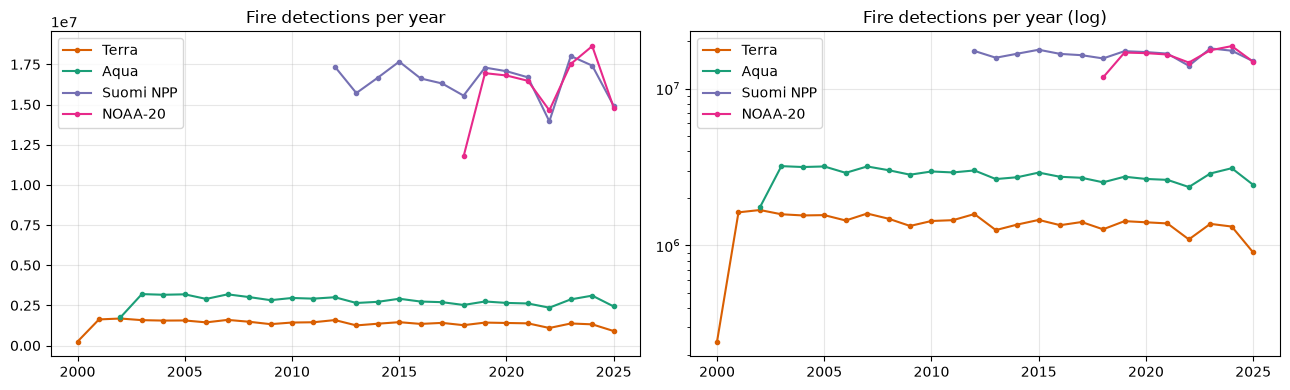

In [41]:
annual = q("""
    SELECT satellite, instrument, yr, sum(n_all) AS n_all, sum(n_veg) AS n_veg,
           sum(n_fire) AS n_fire, sum(frp_fire) AS frp_fire
    FROM sm GROUP BY ALL ORDER BY satellite, yr
""")
n_fire = annual.pivot(index="yr", columns="satellite", values="n_fire").reindex(columns=SATS)
frp_fire = annual.pivot(index="yr", columns="satellite", values="frp_fire").reindex(columns=SATS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, log in zip(axes, [False, True]):
    for s in SATS:
        n_fire.loc[:2025, s].dropna().plot(ax=ax, color=SAT_COLOR[s], marker="o", ms=3, label=s)
    ax.set_yscale("log" if log else "linear")
    ax.set_title("Fire detections per year" + (" (log)" if log else ""))
    ax.set_xlabel("")
    ax.legend()
plt.tight_layout()
(n_fire.loc[:2025] / 1e6).round(2)

In [42]:
# Share of detections kept at each filter step, per satellite (2019 to 2025 = common period).
keep = annual[annual.yr.between(2019, 2025)].groupby("satellite")[["n_all", "n_veg", "n_fire"]].sum()
keep["pct_non_veg"] = 100 * (1 - keep.n_veg / keep.n_all)
keep["pct_low_conf_of_veg"] = 100 * (1 - keep.n_fire / keep.n_veg)
keep["pct_kept"] = 100 * keep.n_fire / keep.n_all
keep.loc[SATS]

,n_all,n_veg,n_fire,pct_non_veg,pct_low_conf_of_veg,pct_kept
satellite,,,,,,
Terra,"10,182,487.000","9,451,868.000","8,896,506.000",7.175,5.876,87.371
Aqua,"20,216,109.000","19,631,312.000","18,776,252.000",2.893,4.356,92.878
Suomi NPP,"140,167,002.000","130,769,325.000","115,366,643.000",6.705,11.779,82.307
NOAA-20,"141,407,577.000","131,881,681.000","115,831,831.000",6.736,12.170,81.913


## 7. Monthly series per satellite

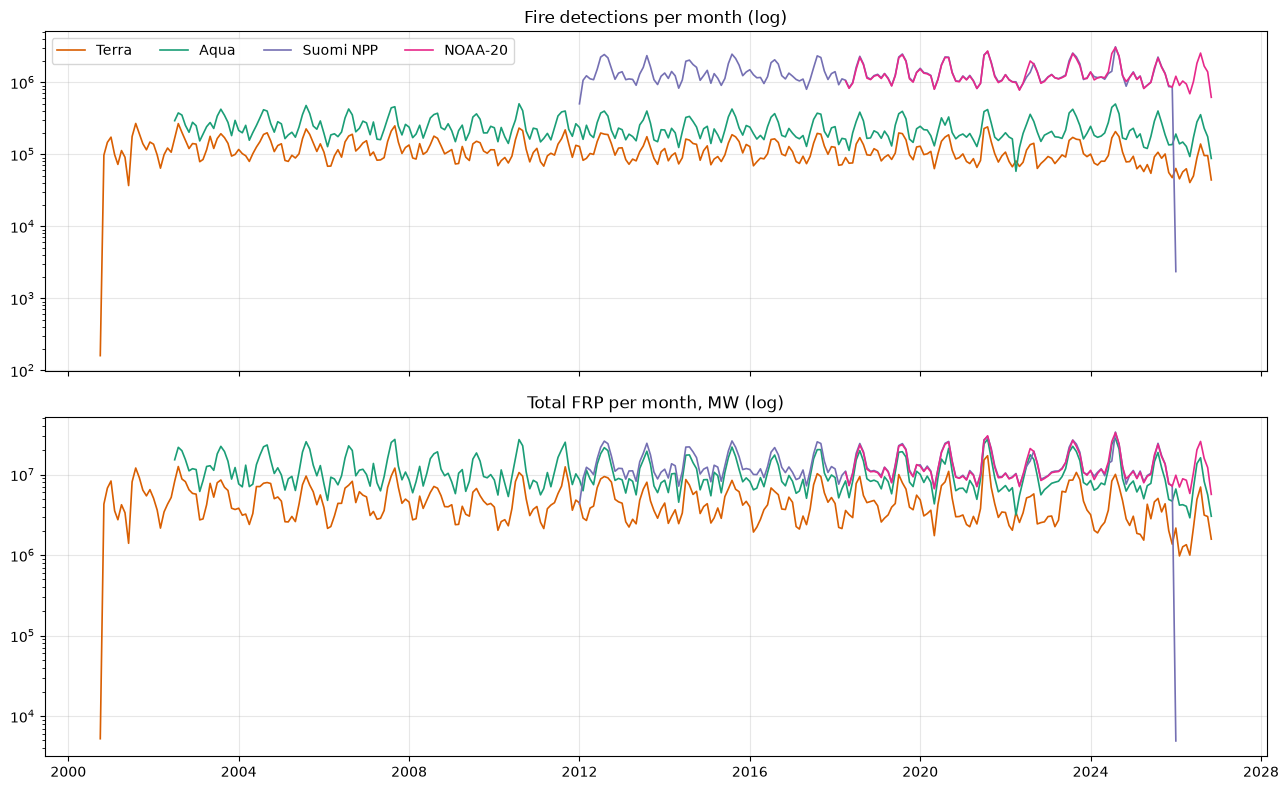

In [43]:
monthly = q("""
    SELECT satellite, make_date(yr, mo, 1) AS month, sum(n_fire) AS n_fire, sum(frp_fire) AS frp_fire
    FROM sm GROUP BY ALL ORDER BY month
""")
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, col, title in zip(axes, ["n_fire", "frp_fire"], ["Fire detections per month (log)", "Total FRP per month, MW (log)"]):
    p = monthly.pivot(index="month", columns="satellite", values=col).reindex(columns=SATS)
    for s in SATS:
        ax.plot(p.index, p[s], color=SAT_COLOR[s], label=s, lw=1.2)
    ax.set_yscale("log")
    ax.set_title(title)
axes[0].legend(ncol=4)
plt.tight_layout()

## 8. Cross-sensor ratios

Ratios of one satellite to another, never sums. Compare the count ratio with the FRP ratio: a stable ratio is easier to harmonize.

counts                                                              FRP                                                  
     NOAA-20 / Aqua Suomi NPP / Aqua Suomi NPP / NOAA-20 Aqua / Terra NOAA-20 / Aqua Suomi NPP / Aqua Suomi NPP / NOAA-20 Aqua / Terra
yr                                                                                                                                    
2002            NaN              NaN                 NaN        1.040            NaN              NaN                 NaN        1.290
2003            NaN              NaN                 NaN        2.030            NaN              NaN                 NaN        2.410
2004            NaN              NaN                 NaN        2.040            NaN              NaN                 NaN        2.450
2005            NaN              NaN                 NaN        2.040            NaN              NaN                 NaN        2.540
2006            NaN              NaN                 NaN        2.010            NaN              NaN                 NaN        2.370
2007            NaN              NaN                 NaN        2.000            NaN              NaN                 NaN        2.350
2008            NaN              NaN                 NaN        2.040            NaN              NaN                 NaN        2.390
2009            NaN              NaN                 NaN        2.120            NaN              NaN                 NaN        2.510
2010            NaN              NaN                 NaN        2.070            NaN              NaN                 NaN        2.430
2011            NaN              NaN                 NaN        2.010            NaN              NaN                 NaN        2.240
2012            NaN            5.780                 NaN        1.900            NaN            1.200                 NaN        2.090
2013            NaN            5.930                 NaN        2.110            NaN            1.320                 NaN        2.420
2014            NaN            6.130                 NaN        2.000            NaN            1.340                 NaN        2.280
2015            NaN            6.070                 NaN        2.000            NaN            1.300                 NaN        2.310
2016            NaN            6.070                 NaN        2.030            NaN            1.330                 NaN        2.380
2017            NaN            6.040                 NaN        1.910            NaN            1.270                 NaN        2.110
2018          4.660            6.160               1.320        1.990          1.020            1.310               1.280        2.150
2019          6.180            6.310               1.020        1.920          1.260            1.290               1.020        2.210
2020          6.340            6.440               1.020        1.890          1.340            1.370               1.020        2.120
2021          6.290            6.380               1.010        1.900          1.250            1.270               1.020        1.960
2022          6.210            5.920               0.950        2.160          1.350            1.290               0.950        2.580
2023          6.100            6.270               1.030        2.090          1.220            1.260               1.030        2.110
2024          6.000            5.610               0.930        2.350          1.250            1.170               0.940        2.830
2025          6.090            6.130               1.010        2.700          1.370            1.390               1.010        2.910

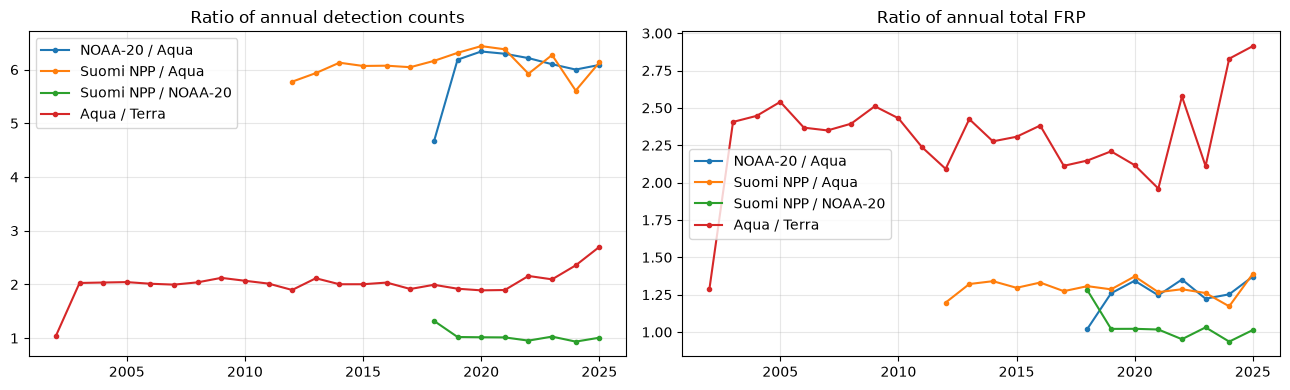

In [44]:
def ratio_table(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "NOAA-20 / Aqua": df["NOAA-20"] / df["Aqua"],
        "Suomi NPP / Aqua": df["Suomi NPP"] / df["Aqua"],
        "Suomi NPP / NOAA-20": df["Suomi NPP"] / df["NOAA-20"],
        "Aqua / Terra": df["Aqua"] / df["Terra"],
    }).loc[:2025].dropna(how="all")


r_n, r_f = ratio_table(n_fire), ratio_table(frp_fire)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
r_n.plot(ax=axes[0], marker="o", ms=3, title="Ratio of annual detection counts")
r_f.plot(ax=axes[1], marker="o", ms=3, title="Ratio of annual total FRP")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
pd.concat({"counts": r_n, "FRP": r_f}, axis=1).round(2)

mo,1,2,3,4,5,6,7,8,9,10,11,12
mean,6.120,6.250,6.330,8.030,6.560,5.210,5.540,6.330,6.370,6.930,6.550,5.820
min,5.700,5.900,6.020,6.290,5.840,4.840,4.950,5.450,5.880,6.730,6.310,5.480
max,6.380,6.760,6.690,17.050,7.530,5.680,6.010,8.700,6.820,7.350,6.880,6.270


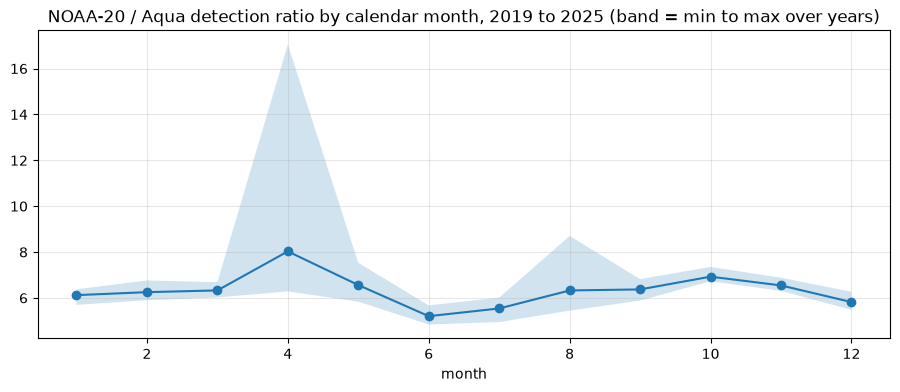

In [45]:
# By calendar month, 2019 to 2025: mean ratio with min/max across years. A flat line would mean one global factor works.
mm = q("""
    SELECT satellite, yr, mo, sum(n_fire) AS n
    FROM sm WHERE satellite IN ('NOAA-20', 'Aqua') AND yr BETWEEN 2019 AND 2025 GROUP BY ALL
""").pivot(index=["yr", "mo"], columns="satellite", values="n")
mm["ratio"] = mm["NOAA-20"] / mm["Aqua"]
by_mo = mm.ratio.groupby("mo").agg(["mean", "min", "max"])
ax = by_mo["mean"].plot(marker="o", title="NOAA-20 / Aqua detection ratio by calendar month, 2019 to 2025 (band = min to max over years)")
ax.fill_between(by_mo.index, by_mo["min"], by_mo["max"], alpha=0.2)
ax.set_xlabel("month")
by_mo.round(2).T

count   93.000
mean     0.993
std      0.123
min      0.002
25%      1.007
50%      1.015
75%      1.022
max      1.107


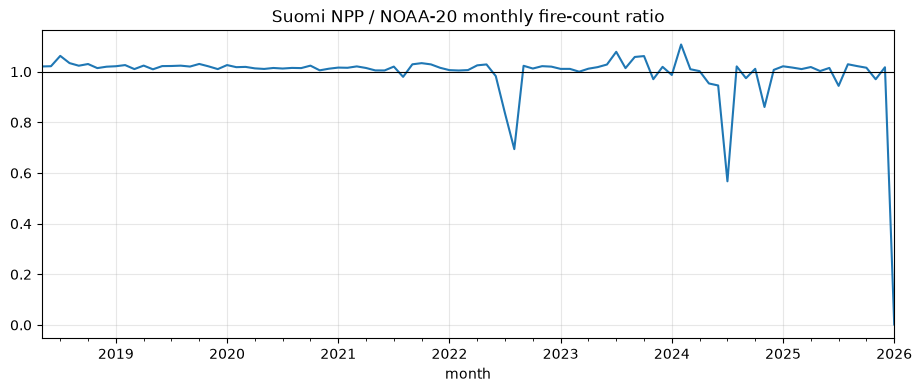

In [46]:
# Suomi NPP vs NOAA-20 over their overlap (2018-05 onward): the brief expects about 1:1 but has not measured it.
ov = q("""
    SELECT satellite, make_date(yr, mo, 1) AS month, sum(n_fire) AS n
    FROM sm WHERE satellite IN ('Suomi NPP', 'NOAA-20') AND make_date(yr, mo, 1) >= DATE '2018-05-01' GROUP BY ALL
""").pivot(index="month", columns="satellite", values="n")
snpp_n20 = (ov["Suomi NPP"] / ov["NOAA-20"]).dropna()
ax = snpp_n20.plot(title="Suomi NPP / NOAA-20 monthly fire-count ratio")
ax.axhline(1, color="k", lw=0.8)
print(snpp_n20.describe().round(3).to_string())

## 9. Day and night

satellite,Terra,Aqua,Suomi NPP,NOAA-20
yr,,,,
2000,0.861,NaN,NaN,NaN
2001,0.812,NaN,NaN,NaN
2002,0.778,0.936,NaN,NaN
2003,0.785,0.954,NaN,NaN
2004,0.784,0.952,NaN,NaN
2005,0.781,0.953,NaN,NaN
2006,0.794,0.954,NaN,NaN
2007,0.780,0.949,NaN,NaN
2008,0.811,0.961,NaN,NaN


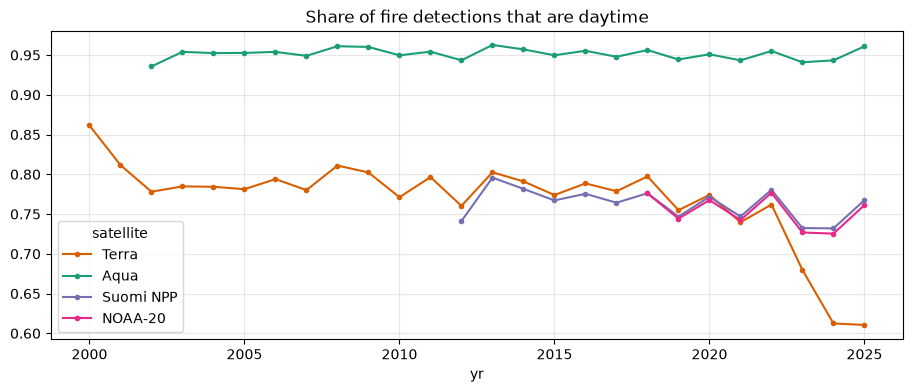

In [47]:
dn = q("""
    SELECT satellite, yr, sum(n_fire) FILTER (WHERE daynight = 'D') / sum(n_fire) AS day_share
    FROM sm GROUP BY ALL
""").pivot(index="yr", columns="satellite", values="day_share").reindex(columns=SATS).loc[:2025]
dn.plot(color=[SAT_COLOR[s] for s in SATS], marker="o", ms=3, title="Share of fire detections that are daytime")
dn.round(3)

## 10. Fire radiative power

FRP per detection is a different quantity from the count: it measures intensity. Distribution is skewed, so look at quantiles (approximate, streaming, to stay inside the memory limit). Scans 2024 (August only when `QUICK`; two columns).

In [48]:
frp_q = q(f"""
    SELECT satellite,
           count(*) AS n,
           avg(frp) AS mean,
           approx_quantile(frp, 0.10) AS p10, approx_quantile(frp, 0.50) AS p50,
           approx_quantile(frp, 0.90) AS p90, approx_quantile(frp, 0.99) AS p99,
           max(frp) AS max
    FROM {SILVER}
    WHERE {in_year(2024)} AND {FIRE}
    GROUP BY satellite
""").set_index("satellite").loc[SATS]
frp_q

,n,mean,p10,p50,p90,p99,max
satellite,,,,,,,
Terra,1318825,38.548,6.608,17.224,75.059,364.103,"12,423.700"
Aqua,3105296,46.310,8.116,21.476,90.674,425.577,"11,891.800"
Suomi NPP,17424488,9.674,1.298,5.305,19.751,80.682,"12,470.230"
NOAA-20,18634195,9.667,1.292,5.280,19.222,83.430,"2,825.180"


## 11. Local overpass time (orbit drift)

Local solar hour of each detection (UTC plus longitude / 15). Terra drifts earlier after 2020 and Aqua later after 2022, so compare 2019 with 2025. Scans 2019 and 2025 (August only when `QUICK`).

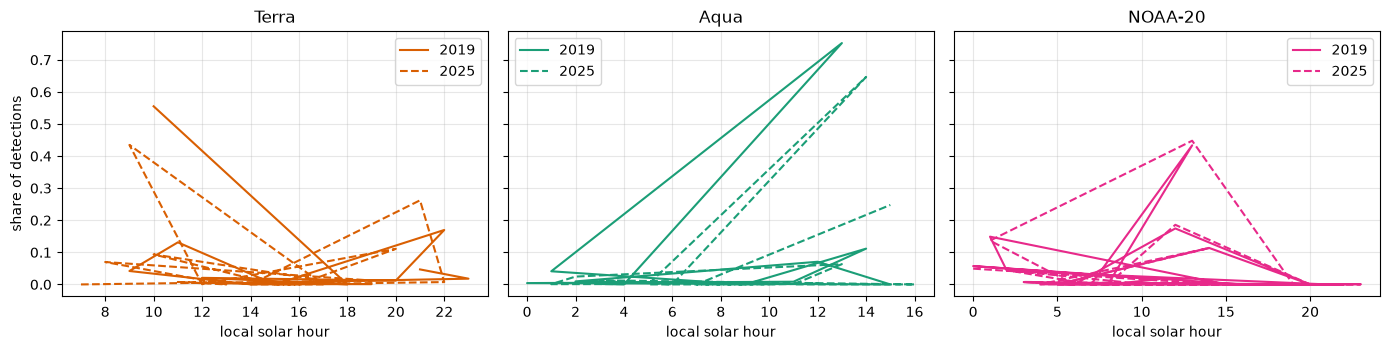

In [49]:
hrs = q(f"""
    SELECT satellite, year, hour(acq_datetime_utc + to_seconds(longitude * 240)) AS local_hour, count(*) AS n
    FROM {SILVER}
    WHERE ({in_year(2019)} OR {in_year(2025)}) AND source IN ('modis', 'viirs_noaa20') AND {FIRE}
    GROUP BY ALL
""")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, s in zip(axes, ["Terra", "Aqua", "NOAA-20"]):
    for y, ls in [(2019, "-"), (2025, "--")]:
        d = hrs[(hrs.satellite == s) & (hrs.year == y)].set_index("local_hour").n
        ax.plot(d.index, d / d.sum(), ls, color=SAT_COLOR[s], label=str(y))
    ax.set_title(s)
    ax.set_xlabel("local solar hour")
    ax.legend()
axes[0].set_ylabel("share of detections")
plt.tight_layout()

## 12. Pixel size (view angle)

`scan` is the along-scan pixel size in km; it grows towards the swath edge and lowers sensitivity. Share of detections per scan bin, 2024 (August only when `QUICK`). Scans 2024.

,mean_scan_km
satellite,
Aqua,1.568
NOAA-20,0.415
Terra,1.552


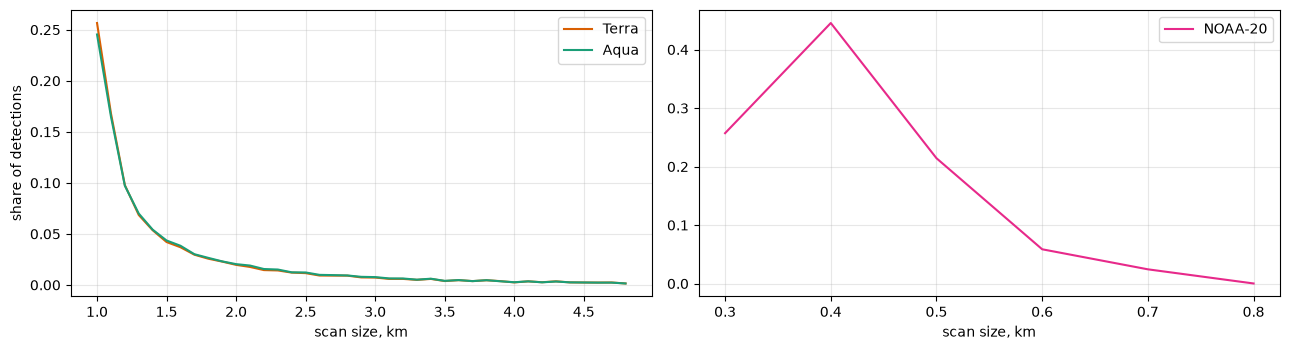

In [50]:
scan = q(f"""
    SELECT satellite, floor(scan * 10) / 10 AS scan_km, count(*) AS n
    FROM {SILVER}
    WHERE {in_year(2024)} AND source IN ('modis', 'viirs_noaa20') AND {FIRE}
    GROUP BY ALL
""")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, sats in zip(axes, [["Terra", "Aqua"], ["NOAA-20"]]):
    for s in sats:
        d = scan[scan.satellite == s].set_index("scan_km").n.sort_index()
        ax.plot(d.index, d / d.sum(), color=SAT_COLOR[s], label=s)
    ax.set_xlabel("scan size, km")
    ax.legend()
axes[0].set_ylabel("share of detections")
plt.tight_layout()
scan.groupby("satellite").apply(lambda g: pd.Series({"mean_scan_km": np.average(g.scan_km, weights=g.n)}), include_groups=False)

## 13. Countries

Country is the likely calibration unit. Check how well it is populated, and how much the VIIRS / MODIS ratio varies between countries.

In [51]:
cq = q("""
    SELECT satellite, quality,
           100 * sum(n_all) FILTER (WHERE country IS NULL OR country = '') / sum(n_all) AS pct_no_country
    FROM sm GROUP BY ALL ORDER BY satellite, quality
""")
cq

,satellite,quality,pct_no_country
0,Aqua,NRT,0.255
1,Aqua,SP,0.005
2,NOAA-20,NRT,0.322
3,NOAA-20,SP,0.017
4,Suomi NPP,SP,NaN
5,Terra,NRT,0.534
6,Terra,SP,0.010


satellite,Aqua,NOAA-20,Terra,NOAA-20 / Aqua,share_of_global_%
country,,,,,
Democratic_Republic_of_the_Congo,"2,609,201.000","12,204,709.000","492,495.000",4.680,10.540
Brazil,"1,479,668.000","8,953,693.000","955,388.000",6.050,7.730
Angola,"1,846,898.000","7,782,044.000","377,857.000",4.210,6.720
Australia,"924,823.000","7,216,993.000","646,881.000",7.800,6.230
Russian_Federation,"755,077.000","7,111,934.000","873,271.000",9.420,6.140
Zambia,"950,770.000","4,881,627.000","326,498.000",5.130,4.210
Mozambique,"745,245.000","4,445,446.000","160,083.000",5.970,3.840
Canada,"332,088.000","3,965,788.000","368,445.000",11.940,3.420
South_Sudan,"696,775.000","3,933,456.000","384,909.000",5.650,3.400


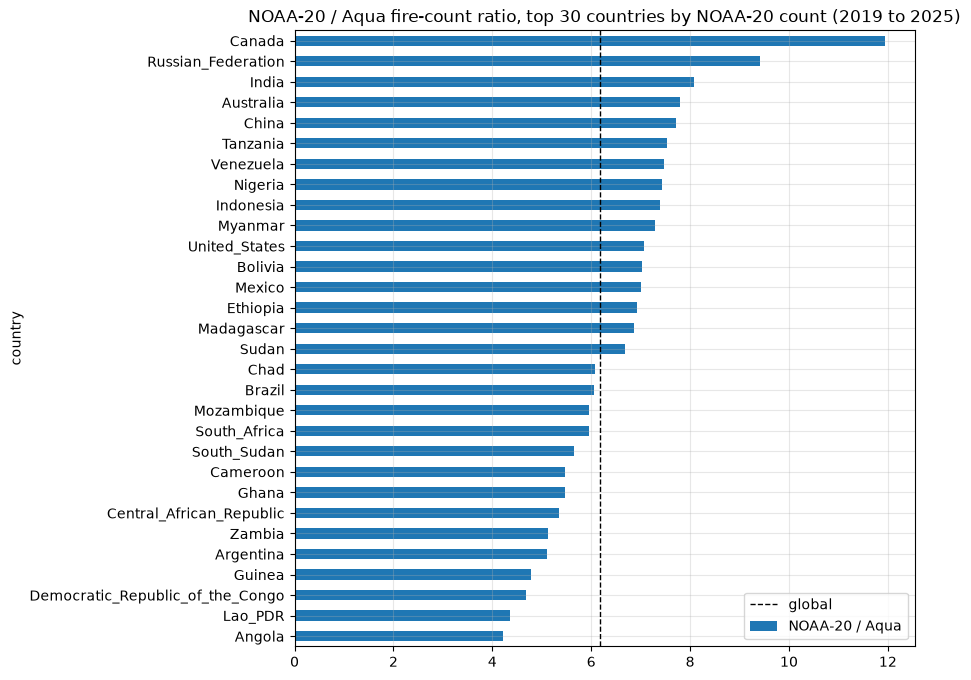

In [52]:
cty = q("""
    SELECT country, satellite, sum(n_fire) AS n
    FROM sm WHERE yr BETWEEN 2019 AND 2025 AND satellite IN ('NOAA-20', 'Aqua', 'Terra') GROUP BY ALL
""").pivot(index="country", columns="satellite", values="n").fillna(0)
cty["NOAA-20 / Aqua"] = cty["NOAA-20"] / cty["Aqua"]
cty["share_of_global_%"] = 100 * cty["NOAA-20"] / cty["NOAA-20"].sum()
top = cty.sort_values("NOAA-20", ascending=False).head(30)
ax = top["NOAA-20 / Aqua"].sort_values().plot.barh(figsize=(8, 8), title="NOAA-20 / Aqua fire-count ratio, top 30 countries by NOAA-20 count (2019 to 2025)")
ax.axvline(cty["NOAA-20"].sum() / cty["Aqua"].sum(), color="k", ls="--", lw=1, label="global")
ax.legend()
top.round(2)

In [53]:
# How concentrated is fire? Cumulative share by country rank (NOAA-20, 2019 to 2025).
cum = cty["NOAA-20"].sort_values(ascending=False).cumsum() / cty["NOAA-20"].sum()
print({k: int((cum < v).sum() + 1) for k, v in [("50%", .5), ("80%", .8), ("95%", .95)]}, "countries cover that share")
print(f"{len(cty)} countries in the cube")

{'50%': 9, '80%': 25, '95%': 50} countries cover that share
237 countries in the cube


## 14. Argentina burning-activity calendar (prototype)

Year x month fire counts per satellite, each on its own colour scale. With `QUICK` the cube starts in 2019, so only 2019 onward is shown. This is what the app calendar will show once the series is harmonized: the panels are not comparable with each other yet.

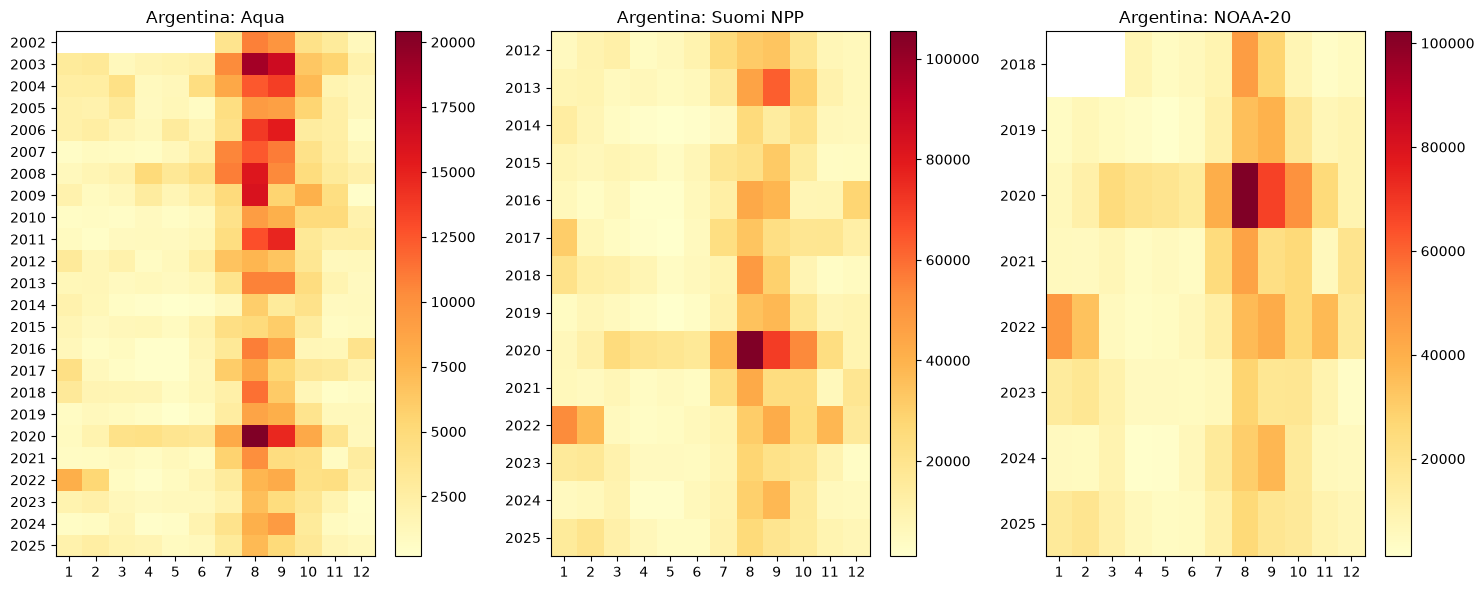

In [54]:
def calendar(country: str, sats: list[str]):
    d = q(f"""
        SELECT satellite, yr, mo, sum(n_fire) AS n FROM sm
        WHERE country = '{country}' AND yr <= 2025 AND satellite IN ({", ".join(repr(s) for s in sats)}) GROUP BY ALL
    """)
    fig, axes = plt.subplots(1, len(sats), figsize=(5 * len(sats), 6))
    for ax, s in zip(np.atleast_1d(axes), sats):
        g = d[d.satellite == s].pivot(index="yr", columns="mo", values="n").reindex(columns=range(1, 13))
        im = ax.imshow(g.values, aspect="auto", cmap="YlOrRd")
        ax.set_yticks(range(len(g.index)), g.index)
        ax.set_xticks(range(12), range(1, 13))
        ax.set_title(f"{country}: {s}")
        ax.grid(False)
        fig.colorbar(im, ax=ax)
    plt.tight_layout()


calendar("Argentina", ["Aqua", "Suomi NPP", "NOAA-20"])

## 15. Detection types (static sources)

Silver `type_final`: 0 vegetation fire, 1 volcano, 2 other static land source, 3 offshore. Percent of all detections, 2024 (August only when `QUICK`). Scans 2024.

In [55]:
types = q(f"""
    SELECT satellite, type_final, count(*) AS n
    FROM {SILVER} WHERE {in_year(2024)} GROUP BY ALL
""").pivot(index="satellite", columns="type_final", values="n").fillna(0).loc[SATS]
(100 * types.div(types.sum(axis=1), axis=0)).round(2)

type_final,0,1,2,3
satellite,,,,
Terra,92.860,0.270,6.790,0.080
Aqua,97.390,0.100,2.480,0.030
Suomi NPP,93.950,0.070,5.640,0.340
NOAA-20,94.020,0.070,5.560,0.350


## 16. SP vs NRT in 2026

NRT rows have no FIRMS `type`, so fire type is inferred from the static lookup (`type_inferred`), and country comes from lookups (`country_source`). The first table reads the cube. The second scans 2026 (August only when `QUICK`).

In [56]:
nrt = q("""
    SELECT satellite, quality, mo, sum(n_fire) AS n_fire
    FROM sm WHERE yr = 2026 GROUP BY ALL
""").pivot(index=["satellite", "quality"], columns="mo", values="n_fire").fillna(0).astype(int)
nrt

mo                      1       2        3       4       5        6        7        8        9        10      11
satellite quality                                                                                               
Aqua      NRT            0       0        0       0       0        0        0        0   228944   175317   87531
          SP        190956  139418   147769  128475   92823   171196   281018   354545      466        0       0
NOAA-20   NRT            0       0        0       0       0        0        0  2526830  1676292  1393067  617591
          SP       1211048  903318  1039380  945022  691840  1022196  1832966    12871        0        0       0
Suomi NPP SP          2350       0        0       0       0        0        0        0        0        0       0
Terra     NRT            0       0        0       0       0        0        0      724    95869    95772   43975
          SP         63568   45590    56823   62940   40442    49944    89122   138057      119        0       0

In [57]:
q(f"""
    SELECT satellite, quality, count(*) AS n,
           100 * avg(type_inferred::INT)                                       AS pct_type_inferred,
           100 * avg((country_source IS NULL OR country_source = '')::INT)     AS pct_no_country,
           100 * avg((country_source IN ('lookup_01deg', 'lookup_1deg'))::INT) AS pct_country_from_lookup
    FROM {SILVER} WHERE {in_year(2026)} GROUP BY ALL ORDER BY satellite, quality
""")

,satellite,quality,n,pct_type_inferred,pct_no_country,pct_country_from_lookup
0,Aqua,NRT,529686,100.000,0.255,100.000
1,Aqua,SP,1634254,0.000,0.231,100.000
2,NOAA-20,NRT,7483416,100.000,0.322,100.000
3,NOAA-20,SP,9559961,0.000,0.288,100.000
4,Terra,NRT,270482,100.000,0.534,100.000
5,Terra,SP,668226,0.000,0.618,100.000


## 17. Spatial pattern

1 degree cells, 2024 (August only when `QUICK`), Aqua vs NOAA-20. Colour is log10 of fire count. Scans 2024.

           cells  detections
satellite                   
Aqua       10185     3105296
NOAA-20    12347    18634195


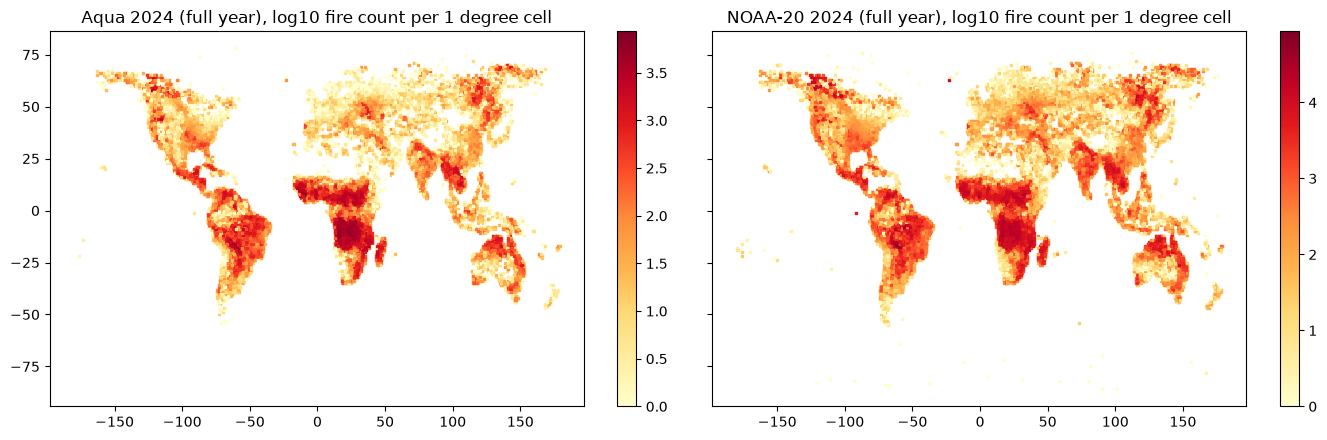

In [58]:
grid = q(f"""
    SELECT satellite, floor(latitude)::INT AS lat, floor(longitude)::INT AS lon, count(*) AS n
    FROM {SILVER}
    WHERE {in_year(2024)} AND source IN ('modis', 'viirs_noaa20') AND satellite IN ('Aqua', 'NOAA-20') AND {FIRE}
    GROUP BY ALL
""")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, sharey=True)
for ax, s in zip(axes, ["Aqua", "NOAA-20"]):
    g = grid[grid.satellite == s]
    sc = ax.scatter(g.lon, g.lat, c=np.log10(g.n), s=2, cmap="YlOrRd", marker="s")
    ax.set_title(f"{s} 2024 ({WIN_TXT}), log10 fire count per 1 degree cell")
    ax.grid(False)
    fig.colorbar(sc, ax=ax)
plt.tight_layout()
print(grid.groupby("satellite").agg(cells=("n", "size"), detections=("n", "sum")))

## 18. Cross-check: silver cube vs `analysis/agg_monthly`

`agg_monthly` is built from bronze (UTC dates, FIRMS type). Annual fire counts should agree with the silver cube except for small differences from local-date year boundaries and the silver type logic.

In [59]:
agg = q(f"""
    SELECT CASE sat WHEN 'N20' THEN 'NOAA-20' ELSE sat END AS satellite, yr, sum(n) AS n_agg
    FROM {AGG} WHERE type = 0 AND conf <> 'low' AND yr BETWEEN 2019 AND 2025 GROUP BY ALL
""").pivot(index="yr", columns="satellite", values="n_agg")
silver_n = n_fire.loc[2019:2025, ["Terra", "Aqua", "NOAA-20"]]
(100 * (silver_n / agg - 1)).round(3).rename_axis("silver vs agg_monthly, % difference")

satellite,Aqua,NOAA-20,Terra
"silver vs agg_monthly, % difference",,,
2019,-0.029,-0.073,0.001
2020,0.027,0.081,0.002
2021,0.001,-0.004,0.012
2022,0.003,0.002,-0.015
2023,-0.010,-0.005,-0.002
2024,0.008,0.000,0.001
2025,0.003,0.004,0.002


## 19. Findings log

Add one line per finding with the number and the section that shows it. Keep this current so conclusions do not live only in chat.

Full run, `QUICK = False`, data as of 2026-11-14. Cube covers the whole record (2000-10 to 2026-11, 256,806 rows, 568,647,228 detections). Row-level sections (null profile, FRP, scan size, types, SP/NRT, spatial) use all of 2024 or 2026; the overpass-hour plot uses 2019 and 2025.

**Coverage (sections 2 and 5)**
- Missing UTC days: Terra 2001 17, 2002 9, 2003 7, 2008 2, 2016 9, 2022 12, 2026 1; Aqua 2002 10, 2022 16; Suomi NPP 2012 1, 2022 15, 2024 19 (five runs); NOAA-20 2023 5, 2024 1. The brief names Aqua and Terra 2022, Terra 2016 and VIIRS 2023; Suomi NPP 2022 and 2024 are new.
- Suomi NPP has almost no 2026 data in silver (2,350 detections, all from Jan 1 local-date spill-over). It is not loaded for 2026.
- Cube first months: Terra 2000-10 (UTC Nov 1 shifts to local Oct 31), Aqua 2002-07, Suomi NPP 2012-01, NOAA-20 2018-04.

**Nulls (section 3)**
- 2024: no nulls in any column. 2026: `country` null in 0.35% (MODIS) and 0.30% (NOAA-20); `type_reported` null in 25.8% (MODIS) and 43.9% (NOAA-20), which is the NRT share (NRT has no FIRMS type).

**Volumes (section 6, fire-filtered counts, millions)**
- Terra 1.25 to 1.68 per year for 2001 to 2021 (2000 is two months), 1.09 (2022), 0.90 (2025). Aqua 2.4 to 3.2 per year from 2003. Suomi NPP 13.95 to 18.0 (2022 low, 2023 high). NOAA-20 14.6 to 18.6 (2019 to 2025). 2025 is genuinely lower than 2024.
- Filters (2019 to 2025): non-vegetation share Terra 7.2%, Aqua 2.9%, VIIRS 6.7%. Low-confidence share of vegetation fires Terra 5.9%, Aqua 4.4%, VIIRS 11.8% to 12.2%. Detections kept: Aqua 92.9%, Terra 87.4%, VIIRS about 82%.

**Ratios (section 8)**
- Global annual Suomi NPP / Aqua count ratio is stable over the whole VIIRS era: 5.6 to 6.4 for 2012 to 2025 (5.78, 5.93, 6.13, 6.07, 6.07, 6.04, 6.16, 6.31, 6.44, 6.38, 5.92, 6.27, 5.61, 6.13). NOAA-20 / Aqua is 6.0 to 6.3 for 2019 to 2025 (2018 is a partial year, ignore). The same ratio on total FRP is 1.17 to 1.39.
- By calendar month (2019 to 2025) the NOAA-20 / Aqua ratio mean runs 5.2 (Jun) to 8.0 (Apr); month-by-year range 4.8 to 17.1. One April hits 17.1 (not yet traced). Season matters; one global factor is too coarse.
- Suomi NPP / NOAA-20 monthly ratio (93 months from 2018-05): median 1.015, interquartile range 1.007 to 1.022, max 1.107. The minimum 0.002 is 2026-01 (Suomi NPP not loaded), an artefact. Annual dips to 0.95 (2022) and 0.93 (2024) are the years with 15 and 19 missing Suomi NPP days.
- Aqua / Terra count ratio: 2.0 to 2.1 for 2003 to 2011 (2002 is a partial Aqua year), 1.9 to 2.1 for 2012 to 2021, then 2.16 (2022), 2.09, 2.35, 2.70 (2025). Same ratio on FRP: 2.1 to 2.5 up to 2021, 2.58 (2022), 2.11 (2023), 2.83 (2024), 2.91 (2025). Terra is drifting away from Aqua.

**Day/night (section 9)**
- Terra daytime share 0.74 to 0.81 for 2001 to 2021 (0.76 in 2022), then 0.68 (2023) and 0.61 (2024, 2025). Aqua 0.94 to 0.96 throughout. VIIRS 0.72 to 0.80. Consistent with Terra's orbit drifting earlier.

**FRP (section 10, 2024)**
- Median FRP per detection: Terra 17.2 MW, Aqua 21.5, Suomi NPP 5.3, NOAA-20 5.3. Mean: Terra 38.5, Aqua 46.3, VIIRS 9.67. 99th percentile: Terra 364, Aqua 426, VIIRS 81 to 83. Maximum: Suomi NPP 12,470 MW (extreme value, check before using FRP sums).

**Pixel size (section 12, 2024)**
- Mean `scan`: Terra 1.55 km, Aqua 1.57 km, NOAA-20 0.42 km.

**Countries (section 13, 2019 to 2025)**
- 237 countries. 9 hold 50% of NOAA-20 fire counts, 25 hold 80%, 50 hold 95%.
- NOAA-20 / Aqua ratio: Angola 4.2, DR Congo 4.7, Guinea 4.8, Zambia 5.1, Argentina 5.1, Brazil 6.1, USA 7.1, Australia 7.8, India 8.1, Russia 9.4, Canada 11.9. It varies by region.
- Country missing for 0.005% to 0.017% of SP rows and 0.26% to 0.53% of NRT rows.

**Detection types (section 15, 2024)**
- Vegetation share: Terra 92.9%, Aqua 97.4%, Suomi NPP 94.0%, NOAA-20 94.0%. Static land source (type 2): Terra 6.8%, Aqua 2.5%, VIIRS 5.6%. Offshore (type 3): VIIRS 0.34% to 0.35%, MODIS 0.03% to 0.08%.

**SP vs NRT (section 16, 2026)**
- NRT starts in August for NOAA-20 and September for Aqua and Terra (Terra has 724 NRT rows in August).
- NRT rows have inferred type (100%); SP rows have none (0%). Country for every 2026 row comes from the lookup (100%); missing for 0.23% to 0.62%.

**Spatial (section 17, 2024)**
- 1 degree cells with fire: Aqua 10,185, NOAA-20 12,347.

**Cross-check (section 18)**
- Silver cube vs `analysis/agg_monthly`, annual fire counts 2019 to 2025: within 0.1% for all satellites.

## 20. Scratch space